# Imagenette: closer to the real world

MNIST is a friendly warm-up. CIFAR-10's 32×32 thumbnails are still toys. Imagenette is the next step up: 10 hand-picked ImageNet classes (tench, English springer, chain saw, church, French horn...), real photos at 160×160, 25× the pixels of CIFAR-10, and much harder.

The plan:

1. Naive CNN baseline: see it struggle
2. Two upgrades: data augmentation + residual blocks (the ResNet recipe from Part 3)
3. Where the resulting model fails
4. What it pays attention to
5. The payoff: watch it engineer its own features

## The data

~9.5k train / ~3.9k val images, cropped to 128×128 from ~160px originals. Normalised with ImageNet channel means/stds (Imagenette is an ImageNet slice). Note `RandomResizedCrop` + `RandomHorizontalFlip` in the train loader; more on that in a moment. (Of the usual upgrade candidates, STL-10 at 2.6 GB and Oxford-IIIT Pet at ~800 MB, Imagenette's ~100 MB download wins the race.)

device: mps


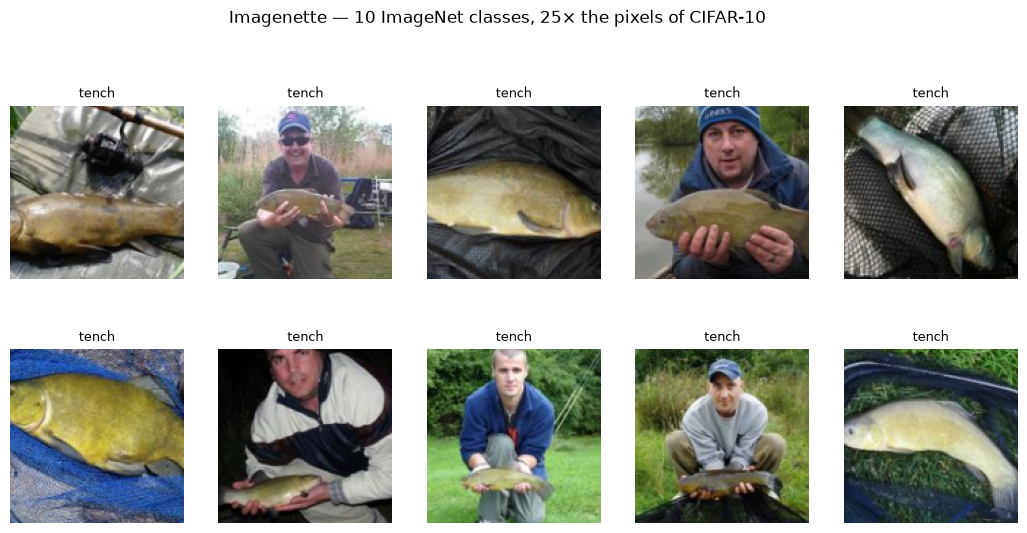

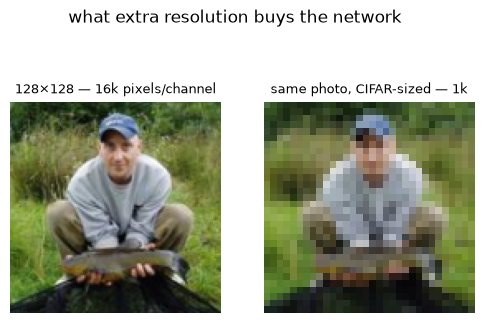

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)  # fix seeds so runs are reproducible
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"device: {device}")

mean = (0.485, 0.456, 0.406)               # ImageNet stats — Imagenette is an ImageNet slice
std = (0.229, 0.224, 0.225)
basic = transforms.Compose([
    transforms.Resize(144), transforms.CenterCrop(128),   # standard square crop
    transforms.ToTensor(), transforms.Normalize(mean, std)])
augment = transforms.Compose([
    transforms.RandomResizedCrop(128, scale=(0.7, 1.0)),   # zoom + shift the object around
    transforms.RandomHorizontalFlip(),                     # mirror it
    transforms.ToTensor(), transforms.Normalize(mean, std),
])

train_aug = torchvision.datasets.Imagenette("data", split="train", size="160px",
                                            download=True, transform=augment)
train_plain = torchvision.datasets.Imagenette("data", split="train", size="160px",
                                              download=True, transform=basic)
test_set = torchvision.datasets.Imagenette("data", split="val", size="160px",
                                           download=True, transform=basic)
classes = [c[0] for c in test_set.classes]   # first synonym is the canonical name

train_plain_loader = torch.utils.data.DataLoader(train_plain, batch_size=128, shuffle=True)
train_aug_loader = torch.utils.data.DataLoader(train_aug, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=256)

x, y = next(iter(test_loader))
# denormalise each image: undo (x - mean) / std
fig, axes = plt.subplots(2, 5, figsize=(13, 5.8))
for ax, img, lab in zip(axes.flat, x, y):  # zip stops after the 10 axes
    ax.imshow((img * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)).permute(1, 2, 0).clamp(0, 1))
    ax.set_title(classes[lab], fontsize=9)
    ax.axis("off")
plt.suptitle("Imagenette — ten ImageNet classes, far more pixels than CIFAR-10", y=1.02)
plt.show()

i = 8   # a nice detailed one
full = (x[i] * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()
tiny = (F.interpolate(x[i][None], size=32, mode="area")[0]
        * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()
fig, axes = plt.subplots(1, 2, figsize=(6, 3.5))
axes[0].imshow(full); axes[0].set_title("full resolution", fontsize=9)
axes[1].imshow(tiny); axes[1].set_title("same photo, CIFAR-sized", fontsize=9)
for ax in axes: ax.axis("off")
plt.suptitle("what extra resolution buys the network", y=1.06)
plt.show()


## Baseline: the naive CNN

Part 3's architecture, stretched to colour and to 128×128: three conv layers and a linear head. Mind the head: after three 2× downsamplings the feature map is 64×16×16 = 16,384 numbers, so the classifier alone is huge. That's it:

In [8]:
class NaiveCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 128 -> 64
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 64 -> 32
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 -> 16
            nn.Flatten(), nn.Linear(64 * 16 * 16, 10),   # 16x16 map per channel -> 10 classes
        )

    def forward(self, x):
        return self.net(x)

naive = NaiveCNN().to(device)
print(f"parameters: {sum(p.numel() for p in naive.parameters()):,}")


parameters: 187,434


In [9]:
def evaluate(model, loader):
    model.eval()  # freeze weights, switch off training behaviour
    correct = 0
    with torch.no_grad():  # no gradients needed for testing
        for x, y in loader:
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(loader.dataset)

def train(model, loader, epochs, lr=1e-3, eval_loader=test_loader):
    opt = torch.optim.AdamW(model.parameters(), lr=lr)   # Adam + decoupled weight decay
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)  # lr glides down to 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()  # clear old gradients
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            opt.step()
        sched.step()  # step the lr schedule once per epoch
        history.append(evaluate(model, eval_loader))
        print(f"epoch {epoch:2d} | test acc {history[-1]:.4f}")
    return history

print("naive CNN, no augmentation:")
naive_hist = train(naive, train_plain_loader, epochs=8)


naive CNN, no augmentation:
epoch  1 | test acc 0.5195
epoch  2 | test acc 0.5730
epoch  3 | test acc 0.6155
epoch  4 | test acc 0.6211
epoch  5 | test acc 0.6222
epoch  6 | test acc 0.6349
epoch  7 | test acc 0.6336
epoch  8 | test acc 0.6408


~64%, flat since epoch 3. Two things to notice: almost 90% of the naive net's parameters sit in that one 16,384→10 linear head, and real photos are just harder: objects move around, lighting varies, breeds and tools look alike. MNIST gave us 98% with a *smaller* net.

## The upgrades

1. Data augmentation: a cheap way to multiply the dataset. `RandomResizedCrop` picks a random zoom/shift window and the flip mirrors it, so the net sees each photo in dozens of variations every epoch. It stops memorising *this* church *here* and starts learning church-ness in general.

2. Residual blocks: Part 3's $y = F(x) + x$, stacked 20 layers deep:

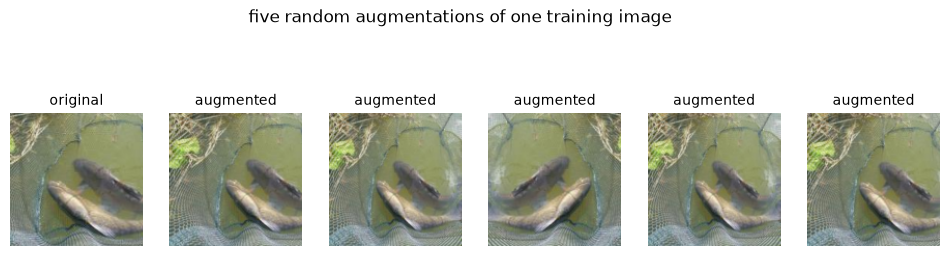

In [10]:
std_t = torch.tensor(std).view(3, 1, 1)
mean_t = torch.tensor(mean).view(3, 1, 1)
def show(t):
    # denormalise a tensor for display
    return (t * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()  # chw -> hwc for imshow

aug_vis = torchvision.datasets.Imagenette("data", split="train", size="160px", transform=augment)
idx = 0   # any image will do
fig, axes = plt.subplots(1, 6, figsize=(12, 2.6))
axes[0].imshow(show(train_plain[idx][0])); axes[0].set_title("original", fontsize=10)
for ax in axes[1:]:
    ax.imshow(show(aug_vis[idx][0])); ax.set_title("augmented", fontsize=10)  # a fresh random crop each time
    ax.axis("off")
axes[0].axis("off")
plt.suptitle("five random augmentations of one training image", y=1.15)
plt.show()


In [11]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
        )
        self.skip = (nn.Identity() if (cin == cout and stride == 1) else
                     nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False),
                                   nn.BatchNorm2d(cout)))  # 1x1 conv matches shape when it changes

    def forward(self, x):
        return F.relu(self.block(x) + self.skip(x))  # the residual addition

class ResNet20(nn.Module):
    # the classic He et al. architecture: 3 stages × 3 blocks, 16/32/64 channels
    # global average pooling means it accepts any input resolution
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(16), nn.ReLU())
        layers, cin = [], 16
        for i, cout in enumerate([16, 32, 64]):
            for b in range(3):
                layers.append(BasicBlock(cin, cout, stride=2 if (i > 0 and b == 0) else 1))  # downsample at each new stage
                cin = cout
        self.blocks = nn.Sequential(*layers)
        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(x.mean(dim=(2, 3)))    # global average pooling: one value per channel

resnet20 = ResNet20().to(device)
print(f"parameters: {sum(p.numel() for p in resnet20.parameters()):,}")


parameters: 272,474


Train it with AdamW and a cosine learning-rate schedule that anneals

$$\eta_t = \tfrac{1}{2}\,\eta_{max}\left(1 + \cos\left(\pi \tfrac{t}{T}\right)\right)$$

AdamW is Adam's adaptive per-parameter step sizes plus *decoupled* weight decay; the W means the weights are shrunk directly instead of through the gradient, so the decay doesn't fight the adaptive lr. The cosine schedule makes steps gentler as we settle into a minimum (15 epochs, a few minutes on GPU/MPS):

In [12]:
print("ResNet-20, with augmentation:")
res_hist = train(resnet20, train_aug_loader, epochs=15, lr=1e-3)

ResNet-20, with augmentation:
epoch  1 | test acc 0.4087
epoch  2 | test acc 0.4357
epoch  3 | test acc 0.5037
epoch  4 | test acc 0.5251
epoch  5 | test acc 0.5187
epoch  6 | test acc 0.6436
epoch  7 | test acc 0.7399
epoch  8 | test acc 0.7019
epoch  9 | test acc 0.6581
epoch 10 | test acc 0.7330
epoch 11 | test acc 0.7447
epoch 12 | test acc 0.7791
epoch 13 | test acc 0.7939
epoch 14 | test acc 0.7870
epoch 15 | test acc 0.8069


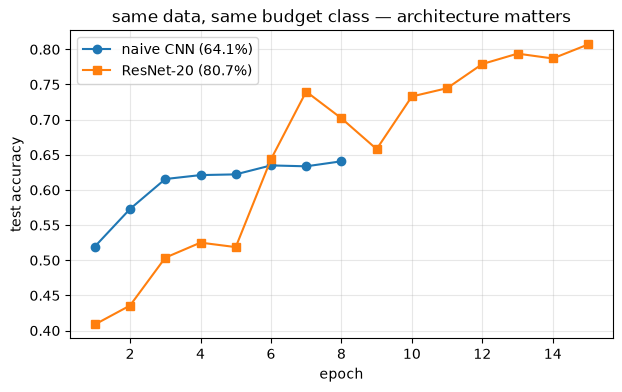

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), naive_hist, "o-", label=f"naive CNN ({naive_hist[-1]:.1%})")
plt.plot(range(1, 16), res_hist, "s-", label=f"ResNet-20 ({res_hist[-1]:.1%})")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("same data, same budget class — architecture matters")
plt.show()

## Where does it fail?

A confusion matrix: rows = true class, columns = prediction. Bright off-diagonal cells = systematic mix-ups:

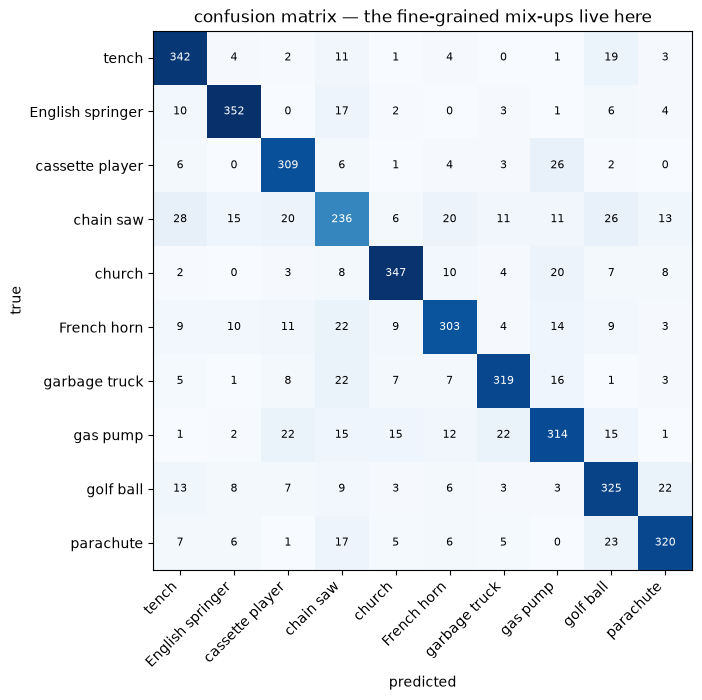

easiest: English springer (89.1%)
hardest: chain saw (61.1%)


In [14]:
resnet20.eval()
conf = np.zeros((10, 10), dtype=int)   # conf[true class, predicted class]
wrong = []
with torch.no_grad():
    for x, y in test_loader:
        pred = resnet20(x.to(device)).argmax(1).cpu()
        for bi, (t, p) in enumerate(zip(y, pred)):
            conf[t, p] += 1
            if t != p and len(wrong) < 8:  # keep a few mistakes for the next plot
                wrong.append((x[bi], t.item(), p.item()))

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(conf, cmap="Blues")
ax.set_xticks(range(10), classes, rotation=45, ha="right")
ax.set_yticks(range(10), classes)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for t in range(10):
    for p in range(10):
        ax.text(p, t, conf[t, p], ha="center", va="center", fontsize=8,
                color="white" if conf[t, p] > conf.max() / 2 else "black")  # keep numbers readable on dark cells
plt.title("confusion matrix — the fine-grained mix-ups live here")
plt.show()

per_class = np.diag(conf) / conf.sum(1)  # recall per class
print("easiest:", classes[per_class.argmax()], f"({per_class.max():.1%})")
print("hardest:", classes[per_class.argmin()], f"({per_class.min():.1%})")


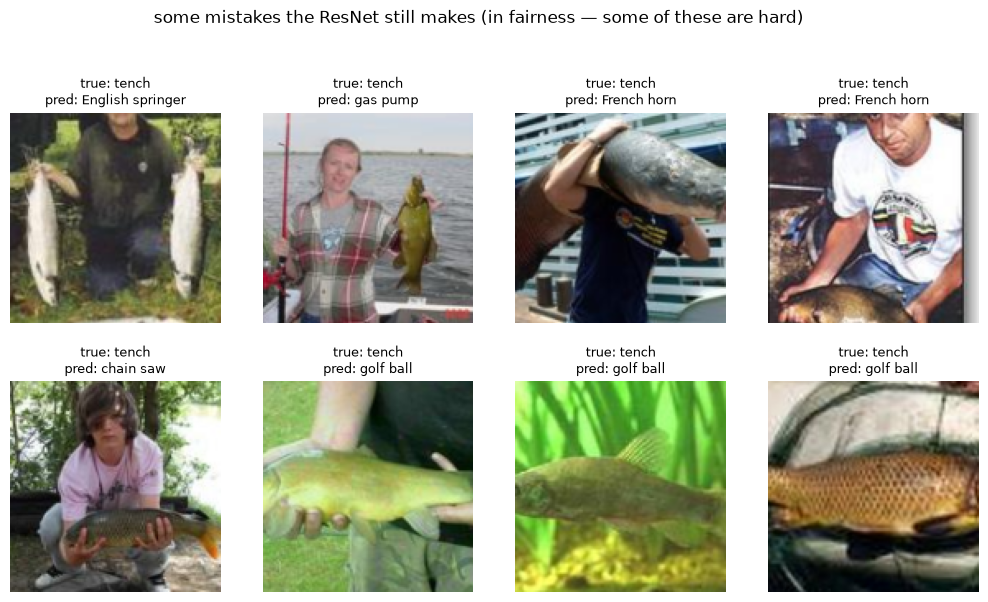

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12.5, 6.4))
for ax, (img, t, p) in zip(axes.flat, wrong):
    ax.imshow(show(img))
    ax.set_title(f"true: {classes[t]}\npred: {classes[p]}", fontsize=9)
    ax.axis("off")
plt.suptitle("some mistakes the ResNet still makes", y=1.03)
plt.show()

## What's it looking at?

The Part 1 saliency trick one last time: gradient of the class score with respect to every pixel, now on colour images:

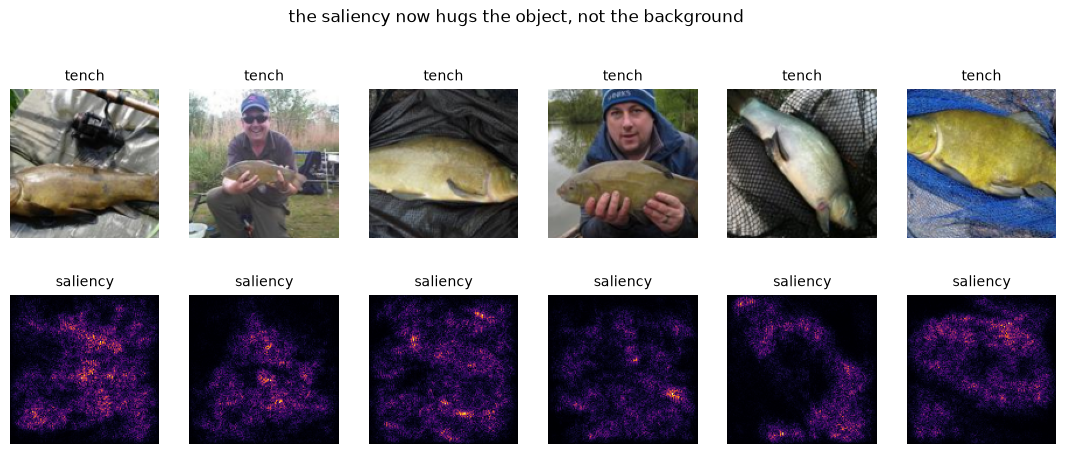

In [16]:
x, y = next(iter(test_loader))
x = x[:6]
x_dev = x.to(device).clone().requires_grad_(True)  # ask for gradients on the input pixels
logits = resnet20(x_dev)
logits.gather(1, logits.argmax(1, keepdim=True)).sum().backward()  # backprop each image's predicted class

sal = x_dev.grad.abs().mean(1).cpu().detach()  # |grad| averaged over colour channels
fig, axes = plt.subplots(2, 6, figsize=(13.5, 4.9))
for i in range(6):
    axes[0, i].imshow(show(x[i]))
    axes[0, i].set_title(classes[y[i]], fontsize=10)
    axes[1, i].imshow(sal[i], cmap="inferno")  # bright = matters to the net
    axes[1, i].set_title("saliency", fontsize=10)
    for r in (0, 1): axes[r, i].axis("off")
plt.suptitle("the saliency now hugs the object, not the background", y=1.02)
plt.show()


## The CNN as feature engineer



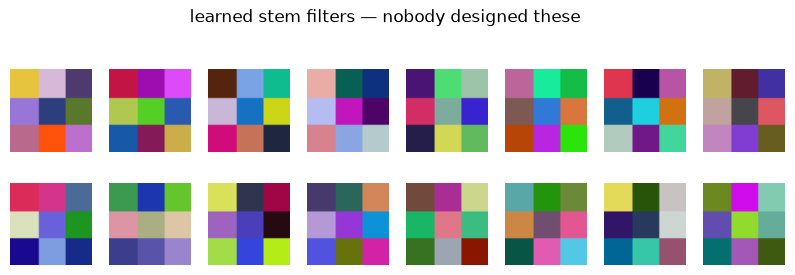

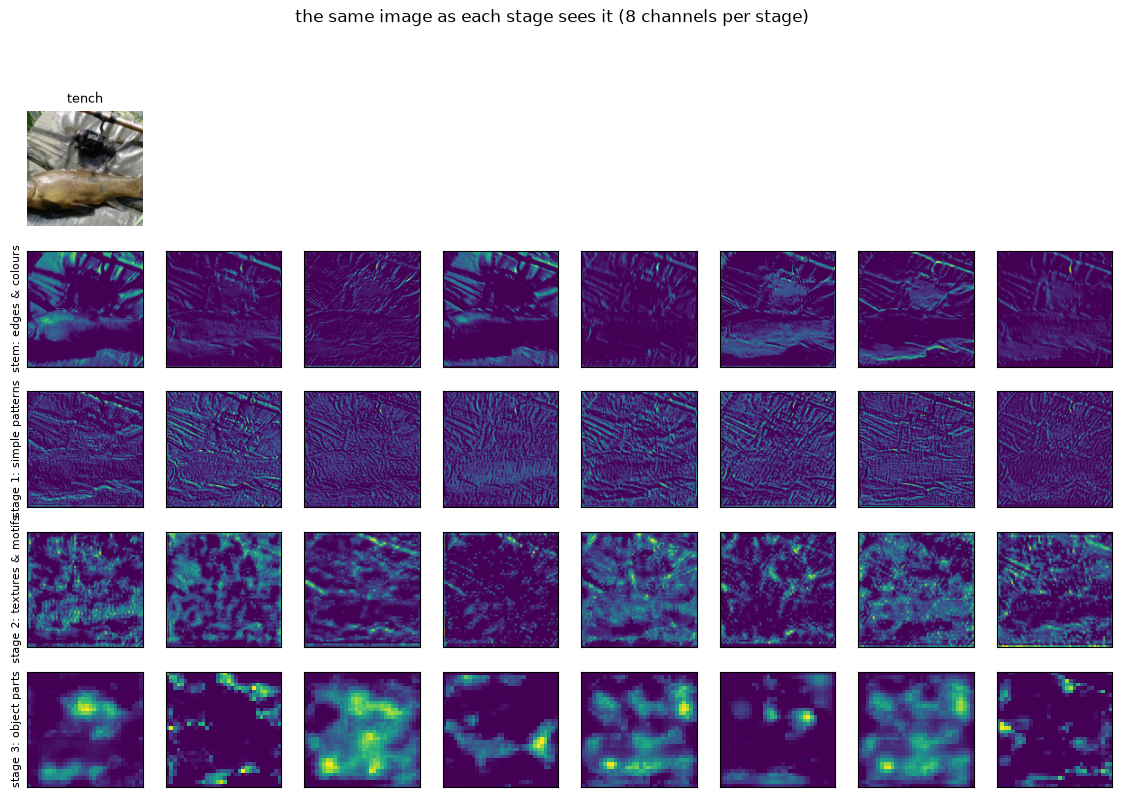

In [17]:
# the stem's 16 learned 3×3 filters, zoomed
w = resnet20.stem[0].weight.detach().cpu()
w = (w - w.min()) / (w.max() - w.min())  # to [0, 1] for display
fig, axes = plt.subplots(2, 8, figsize=(10, 2.7))
for ax, f in zip(axes.flat, w):
    ax.imshow(F.interpolate(f[None], size=40, mode="nearest")[0].permute(1, 2, 0).numpy())  # 3x3 is tiny; upscale to see it
    ax.axis("off")
plt.suptitle("learned stem filters — nobody designed these", y=1.08)
plt.show()

x, y = next(iter(test_loader))
with torch.no_grad():
    s0 = resnet20.stem(x[0][None].to(device))   # one image, add batch dim
    s1 = resnet20.blocks[0:3](s0)   # each stage is one row below
    s2 = resnet20.blocks[3:6](s1)
    s3 = resnet20.blocks[6:9](s2)

stage_names = ["stem: edges & colours", "stage 1: simple patterns",
               "stage 2: textures & motifs", "stage 3: object parts"]
fig, axes = plt.subplots(5, 8, figsize=(14, 8.8))
axes[0, 0].imshow(show(x[0])); axes[0, 0].set_title(classes[y[0]], fontsize=9)
for ax in axes[0]: ax.axis("off")
for r, act in enumerate([s0, s1, s2, s3], start=1):
    for c in range(8):
        a = act[0, c].cpu()
        a = (a - a.min()) / (a.max() - a.min() + 1e-8)  # normalise each map for display
        axes[r, c].imshow(a, cmap="viridis")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(stage_names[r - 1], fontsize=8)
plt.suptitle("the same image as each stage sees it", y=0.995)
plt.show()


Early channels fire on edges and colour blobs; by stage 2 it's textures and repeated motifs; by stage 3, localised object parts. 

Take ~1,000 test images and squash each into 2D, once as raw pixels, once as the 64-dimensional feature vector our classifier actually receives:

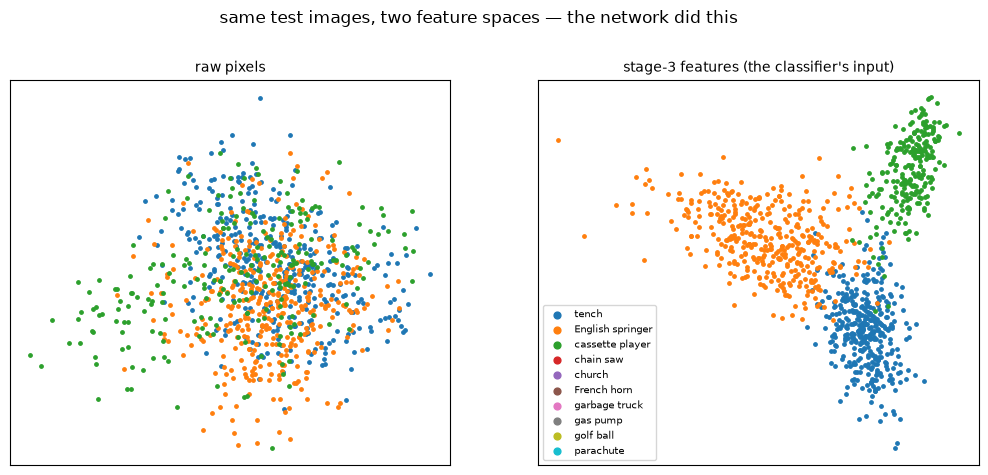

In [18]:
feats, pixels, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_loader:
        h = resnet20.stem(xb.to(device))
        h = resnet20.blocks[0:3](h)
        h = resnet20.blocks[3:6](h)
        h = resnet20.blocks[6:9](h)
        feats.append(h.mean(dim=(2, 3)).cpu())   # what the fc layer actually receives
        pixels.append(xb.flatten(1))
        labels.append(yb)
        if len(labels) * 256 >= 1024: break      # a thousand images is plenty for a scatter

feats, pixels, labels = torch.cat(feats), torch.cat(pixels), torch.cat(labels)

def pca_2d(X):
    X = X - X.mean(0)
    _, _, V = torch.linalg.svd(X, full_matrices=False)  # top 2 right singular vectors
    return (X @ V[:2].T).numpy()                        # project onto them

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, Z, t in zip(axes, [pca_2d(pixels), pca_2d(feats)],
                    ["raw pixels", "stage-3 features (the classifier's input)"]):
    for c in range(10):
        m = labels.numpy() == c   # points of one class share a colour
        ax.scatter(Z[m, 0], Z[m, 1], s=6, label=classes[c])
    ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(fontsize=7, markerscale=2)
plt.suptitle("same test images, two feature spaces — the network did this", y=1.02)
plt.show()


## Takeaways

* Same recipe, real data: the naive CNN that aced MNIST manages ~64% on Imagenette, with ~90% of its parameters parked in one linear head
* Two upgrades fix most of the gap: augmentation (the net can't memorise) and residual blocks + global average pooling (deeper, and a 250× smaller head), together worth the high 70s
* The remaining errors are the *sensible* fine-grained ones: breeds, tools, vehicles
* Saliency now wraps around the object itself, the exact opposite of Part 1's TV static
* X-raying the net: learned edge detectors in the stem, textures by stage 2, object parts by stage 3, and stage-3 features make classes almost linearly separable where raw pixels are soup: feature engineering, automated

The whole workshop in one table:

| Part | Model | Data | Test acc | "Attention" |
|---|---|---|---|---|
| 1 | FNN | MNIST | 97.9% | TV static |
| 3 | 2-layer CNN | MNIST | 98.2% | digit strokes |
| 4 | naive CNN | Imagenette | ~64% | - |
| 4 | ResNet-20 | Imagenette | high 70s | hugs the object |

From "can't see a thing" to "looks at the dog and says English springer", and nobody ever told it what a feature was.